In [1]:
%load_ext autoreload
%autoreload 2

In [84]:
import abc, gc, os, random, re, sys, time, traceback
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stable_baselines3 as sb
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import SubprocVecEnv
from typing import SupportsFloat, Any
import gymnasium as gym
from gymnasium.core import ActType, ObsType
import chime

import faiss
import sklearn
import tqdm
import chime

import torch
from torch.nn import functional as F
from torch.utils import data
from torch import optim

In [3]:
from data_loaders import KuaiRecData, commit_dataset, CommitedDataset, JaggedCommittedDataset, commit_dataset_jagged
from dl_trainer import Trainer, sequence_collate, create_sequence_collator
from rs_algorithm.models import AdaptiveRepresentation
from rs_algorithm.models import TwoTowerRecommender, ThreeTowerRecommenderV2, ConcatInteractionHistoryRepresentationWithUserEmbedInitialization
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel, norm_dot_product_based_relavance_calculation, SimUserModel
from rs_algorithm.system2.environments.env_05_almost_everything import SSREnvironment


In [4]:
data_model = KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [5]:
d_embed = 128
n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]

uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=512, d_embed=d_embed, id2idx=uid2idx)
iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=512, d_embed=d_embed, id2idx=iid2idx)
dot_embed_model = TwoTowerRecommender(user_model, item_model)

Trainer(dot_embed_model, None).load_model('model_id_trained_embedder_v3_128.pt')
dot_embed_model

TwoTowerRecommender(
  (user_model): AdaptiveRepresentation(
    (embedder): Sequential(
      (0): Embedding(1411, 128)
      (1): Flatten(start_dim=1, end_dim=-1)
    )
    (adaptor): Sequential(
      (0): Linear(in_features=1582, out_features=512, bias=True)
      (1): ReLU()
      (2): Linear(in_features=512, out_features=512, bias=True)
      (3): ReLU()
      (4): Linear(in_features=512, out_features=512, bias=True)
      (5): ReLU()
      (6): Dropout(p=0.2, inplace=False)
      (7): Linear(in_features=512, out_features=128, bias=True)
    )
    (alpha): Sequential(
      (0): Linear(in_features=1582, out_features=1, bias=True)
      (1): Sigmoid()
    )
    (bias): Embedding(1411, 1)
  )
  (item_model): AdaptiveRepresentation(
    (embedder): Sequential(
      (0): Embedding(3327, 128)
      (1): Flatten(start_dim=1, end_dim=-1)
    )
    (adaptor): Sequential(
      (0): Linear(in_features=429, out_features=512, bias=True)
      (1): ReLU()
      (2): Linear(in_features=512, 

In [6]:
for mod in (user_model, item_model):
    for par in mod.parameters():
        par.requires_grad = False

history_model = ConcatInteractionHistoryRepresentationWithUserEmbedInitialization(d_embed, 512)
s1recommender = ThreeTowerRecommenderV2(d_embed, user_model, item_model, history_model)

Trainer(s1recommender, None).load_model('model_recommender_v6.pt')
s1recommender

ThreeTowerRecommenderV2(
  (user_model): AdaptiveRepresentation(
    (embedder): Sequential(
      (0): Embedding(1411, 128)
      (1): Flatten(start_dim=1, end_dim=-1)
    )
    (adaptor): Sequential(
      (0): Linear(in_features=1582, out_features=512, bias=True)
      (1): ReLU()
      (2): Linear(in_features=512, out_features=512, bias=True)
      (3): ReLU()
      (4): Linear(in_features=512, out_features=512, bias=True)
      (5): ReLU()
      (6): Dropout(p=0.2, inplace=False)
      (7): Linear(in_features=512, out_features=128, bias=True)
    )
    (alpha): Sequential(
      (0): Linear(in_features=1582, out_features=1, bias=True)
      (1): Sigmoid()
    )
    (bias): Embedding(1411, 1)
  )
  (item_model): AdaptiveRepresentation(
    (embedder): Sequential(
      (0): Embedding(3327, 128)
      (1): Flatten(start_dim=1, end_dim=-1)
    )
    (adaptor): Sequential(
      (0): Linear(in_features=429, out_features=512, bias=True)
      (1): ReLU()
      (2): Linear(in_features=5

In [7]:
index = faiss.IndexFlatIP(d_embed)
idx2iid = {}
with torch.no_grad():
    for idx, iid in enumerate(data_model.ratings['item_id'].unique()):
        item_model.eval()
        iem, *_ = item_model(
            torch.tensor([iid], dtype=torch.int64),
            torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
        index.add(iem.numpy())
        idx2iid[idx] = iid


def get_relevant_items(vector, n=7):
    indices = index.search(vector, n)[1]
    return np.vectorize(idx2iid.get)(indices.flatten())


get_relevant_items(np.random.rand(1, d_embed))

array([6899, 6787, 3974, 7186,  600,  152, 4110])

In [8]:
def get_semi_relevant_items(vector, n=3):
    indices = index.search(vector, 1500 + n)[1]
    return np.vectorize(idx2iid.get)(indices[:, 1500:].flatten())


get_semi_relevant_items(np.random.rand(1, d_embed))

array([4032, 3664, 7731])

In [9]:
def random_perpendicular(v):
    shape = v.shape
    v = v.flatten()
    v = np.asarray(v)
    rand = np.random.randn(*v.shape)  # random vector
    proj = np.dot(rand, v) / np.dot(v, v) * v  # projection of rand onto v
    perp = rand - proj  # subtract projection → perpendicular component
    return perp.reshape(shape)


def get_irrelevant_items(vector, n=7):
    vector = random_perpendicular(vector)
    return get_relevant_items(vector, n)


get_irrelevant_items(np.random.rand(1, d_embed))

array([3916, 2183, 4148, 3098, 5588, 2441, 2671])

In [10]:
def get_random_items(n=2):
    indices = np.random.randint(0, n_items, size=n)
    return np.vectorize(idx2iid.get)(indices)


get_random_items()

array([8545, 3714])

In [11]:
_e = np.random.rand(1, d_embed)
_r = get_relevant_items(_e, 1)
_s = get_semi_relevant_items(_e, 1)
_i = get_irrelevant_items(_e, 1)
_x = get_random_items(1)

with torch.no_grad():
    for _f in (_r, _s, _i, _x):
        iem, *_ = item_model(
            torch.tensor(_f, dtype=torch.int64),
            torch.tensor(data_model.get_item_features(_f), dtype=torch.float32))
        print((F.normalize(torch.tensor(_e), dim=1) * F.normalize(iem, dim=1)).sum(dim=1))

tensor([0.0697], dtype=torch.float64)
tensor([-0.0141], dtype=torch.float64)
tensor([0.0074], dtype=torch.float64)
tensor([-0.0236], dtype=torch.float64)


In [12]:
def create_env():
    return SSREnvironment(
        data_model,
        d_embed,
        user_model,
        item_model,
        s1recommender,
        index,
        idx2iid,
    )

In [58]:
env = make_vec_env(create_env, n_envs=4, vec_env_cls=SubprocVecEnv)

In [59]:
import gc
gc.collect()

97287

In [130]:
# model = sb.DQN("MlpPolicy", env, verbose=1, learning_rate=1e-3, buffer_size=10000, learning_starts=100, batch_size=32)
model = sb.PPO(
    "MlpPolicy", env, verbose=1, learning_rate=3e-4,
    n_steps=2048, batch_size=256, gamma=0.997, ent_coef=0.01,
    policy_kwargs=dict(net_arch=[128, 128]), device='cpu')
model

Using cpu device


In [131]:
model.learn(total_timesteps=15000)
chime.info()

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 1        |
|    ep_rew_mean     | 0.549    |
| time/              |          |
|    fps             | 143      |
|    iterations      | 1        |
|    time_elapsed    | 57       |
|    total_timesteps | 8192     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 1           |
|    ep_rew_mean          | 0.509       |
| time/                   |             |
|    fps                  | 142         |
|    iterations           | 2           |
|    time_elapsed         | 115         |
|    total_timesteps      | 16384       |
| train/                  |             |
|    approx_kl            | 0.012276719 |
|    clip_fraction        | 0.122       |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.6        |
|    explained_variance   | 0.0192      |
|    learning_rate        | 0.

In [139]:
if isinstance(model, sb.DQN):
    model.save("temp/checkpoints/dqn_system_2_v2")
elif isinstance(model, sb.PPO):
    model.save("temp/checkpoints/ppo_system_2_v3")
    print("Hmm")

Hmm


In [136]:
test_env = create_env()
obs, _ = test_env.reset()

rewards = []
recent_click_rates = []
similarities_of_recent_items = []
diversity_scores = []
session_lengths = []

relevance = []
actions = []
fatigue = []
discontent = []

In [137]:
for _ in range(300):
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, done, truncated, info = test_env.step(action)
    rewards.append(reward)
    actions.append(action)
    recent_click_rates.append(info['step_state']['recent_click_rate'])
    similarities_of_recent_items.append(info['step_state']['similarity_of_recent_items'])
    diversity_scores.append(info['step_state']['diversity_score'])
    session_lengths.append(info['step_state']['session_length'])

    relevance.append(info['user_state']['relevance'])
    fatigue.append(info['user_state']['fatigue'])
    discontent.append(info['user_state']['discontent'])
    if done or truncated: break

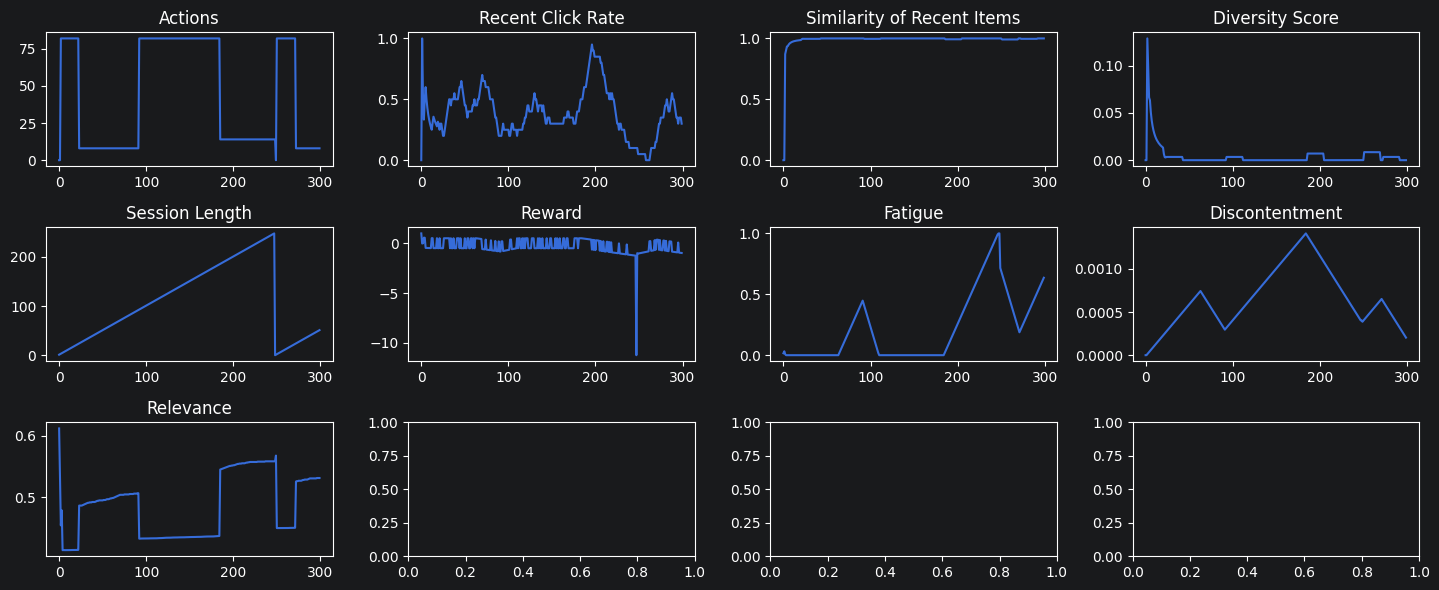

(None, None)

In [138]:
_, axs = plt.subplots(3, 4, figsize=(14.5, 6))
for ax, name, data in zip(axs.ravel(),
                          ('Actions', 'Recent Click Rate', 'Similarity of Recent Items', 'Diversity Score',
                           'Session Length', 'Reward', 'Fatigue', 'Discontentment',
                           'Relevance'),
                          (actions, recent_click_rates, similarities_of_recent_items, diversity_scores,
                           session_lengths, rewards, fatigue, discontent,
                           relevance)):
    ax.plot(data)
    ax.set_title(name)
plt.tight_layout(), plt.show()